# PSMA Tumor Occurrence Map → Any New Patient CT
### Fully Automatic Projection Pipeline
**Yousefirizi & Uribe — EANM 2026**

---

Projects a population-level PSMA TOM (472 patients, autoPET IV) onto any new patient CT.

**Method:**
1. Body-centroid translation aligns template CT to new CT (handles any origin/FOV/spacing)
2. Affine registration refines alignment using correlation metric
3. TOM is upsampled and warped into new CT space
4. Body mask removes background artifacts
5. MIP visualizations with physically correct aspect ratios

**Usage:** Set `NEW_CT_PATH` in Cell 2 → Run All. Accepts `.nii.gz` or DICOM folders.

**Required shared files:**
- `TOM_probability_map_v2.nii.gz` — population TOM
- `TOM_template_ct_fullres.nii.gz` — representative CT from TOM construction

**Outputs:**
| File | Description |
|------|-------------|
| `TOM_warped.nii.gz` | Probability map in new-CT space |
| `TOM_warped_binary.nii.gz` | Binary mask (P > 0.5%) |
| `QC_alignment.png` | Red/cyan body overlap verification |
| `TOM_MIP_overlay.png` | Publication-quality MIP figure |


In [ ]:
# ─── Cell 1 · Install ────────────────────────────────────────────────────────
%pip install -q SimpleITK numpy matplotlib


In [ ]:
# ─── Cell 2 · Configuration ──────────────────────────────────────────────────
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

from pathlib import Path

# ┌────────────────────────────────────────────────────────────────────────────┐
# │  TOM artefacts (shared with this notebook — do NOT change)                │
# └────────────────────────────────────────────────────────────────────────────┘
TOM_DIR          = Path("/content/drive/MyDrive/FYR/results_psma_TOM")
TOM_PATH         = TOM_DIR / "TOM_probability_map_v2.nii.gz"
TEMPLATE_CT_PATH = TOM_DIR / "TOM_template_ct_fullres.nii.gz"

# ┌────────────────────────────────────────────────────────────────────────────┐
# │  NEW PATIENT CT — CHANGE THIS FOR EACH PATIENT                           │
# │  Accepts .nii.gz   OR   a folder containing a DICOM series               │
# └────────────────────────────────────────────────────────────────────────────┘
NEW_CT_PATH = "/content/drive/MyDrive/FYR/new_patient_tom/CT.nii.gz"

# ─── Output (auto-named from parent folder) ───────────────────────────────
CT_LABEL = Path(NEW_CT_PATH).parent.name
SAVE_DIR = Path(f"/content/drive/MyDrive/FYR/TOM_projected/{CT_LABEL}")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("Checking inputs:")
all_ok = True
for label, p in [("TOM", TOM_PATH), ("Template CT", TEMPLATE_CT_PATH),
                  ("New CT", NEW_CT_PATH)]:
    exists = Path(p).exists()
    if not exists:
        all_ok = False
    print(f"  {'OK' if exists else 'MISSING':>7s}  {label}:  {Path(p).name}")
if not all_ok:
    raise FileNotFoundError("Fix the missing paths above before continuing.")
print(f"\nOutput: {SAVE_DIR}")
print("Ready — run Cell 3.")


Mounted at /content/drive
Checking inputs:
       OK  TOM:  TOM_probability_map_v2.nii.gz
       OK  Template CT:  TOM_template_ct_fullres.nii.gz
       OK  New CT:  CT.nii.gz

Output: /content/drive/MyDrive/FYR/TOM_projected/new_patient_tom
Ready — run Cell 3.


  PSMA TOM Projection Pipeline

[1/5] Loading images ...
  TOM         : (100, 100, 214)  spacing=[8.1, 8.1, 4.0] mm
  Template CT : (200, 200, 429)  spacing=[4.1, 4.1, 2.0] mm
  New CT      : (400, 400, 577)  spacing=[2.0, 2.0, 3.0] mm

[2/5] Registration ...
  Centroid offset: dx=+8.6  dy=+44.2  dz=-1899.7 mm
  Registration grid: (100, 100, 144)
  Affine metric: -0.31874  (negative = good)
  Result: centroid + affine

[3/5] Alignment QC ...


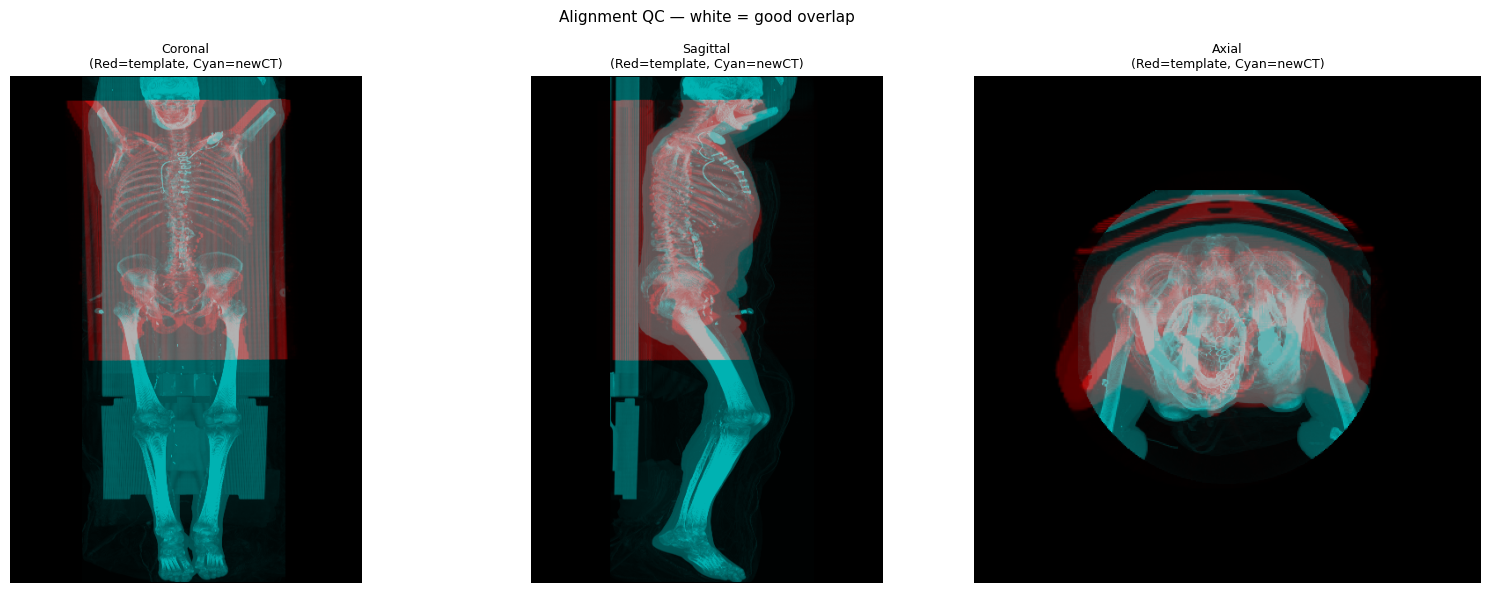

  Saved: QC_alignment.png

[4/5] Projecting TOM ...
  Range    : [0.0000, 0.0786]
  Non-zero : 2,952,090 (3.20%)
  Saved: TOM_warped.nii.gz
  Saved: TOM_warped_binary.nii.gz

[5/5] MIP figures ...


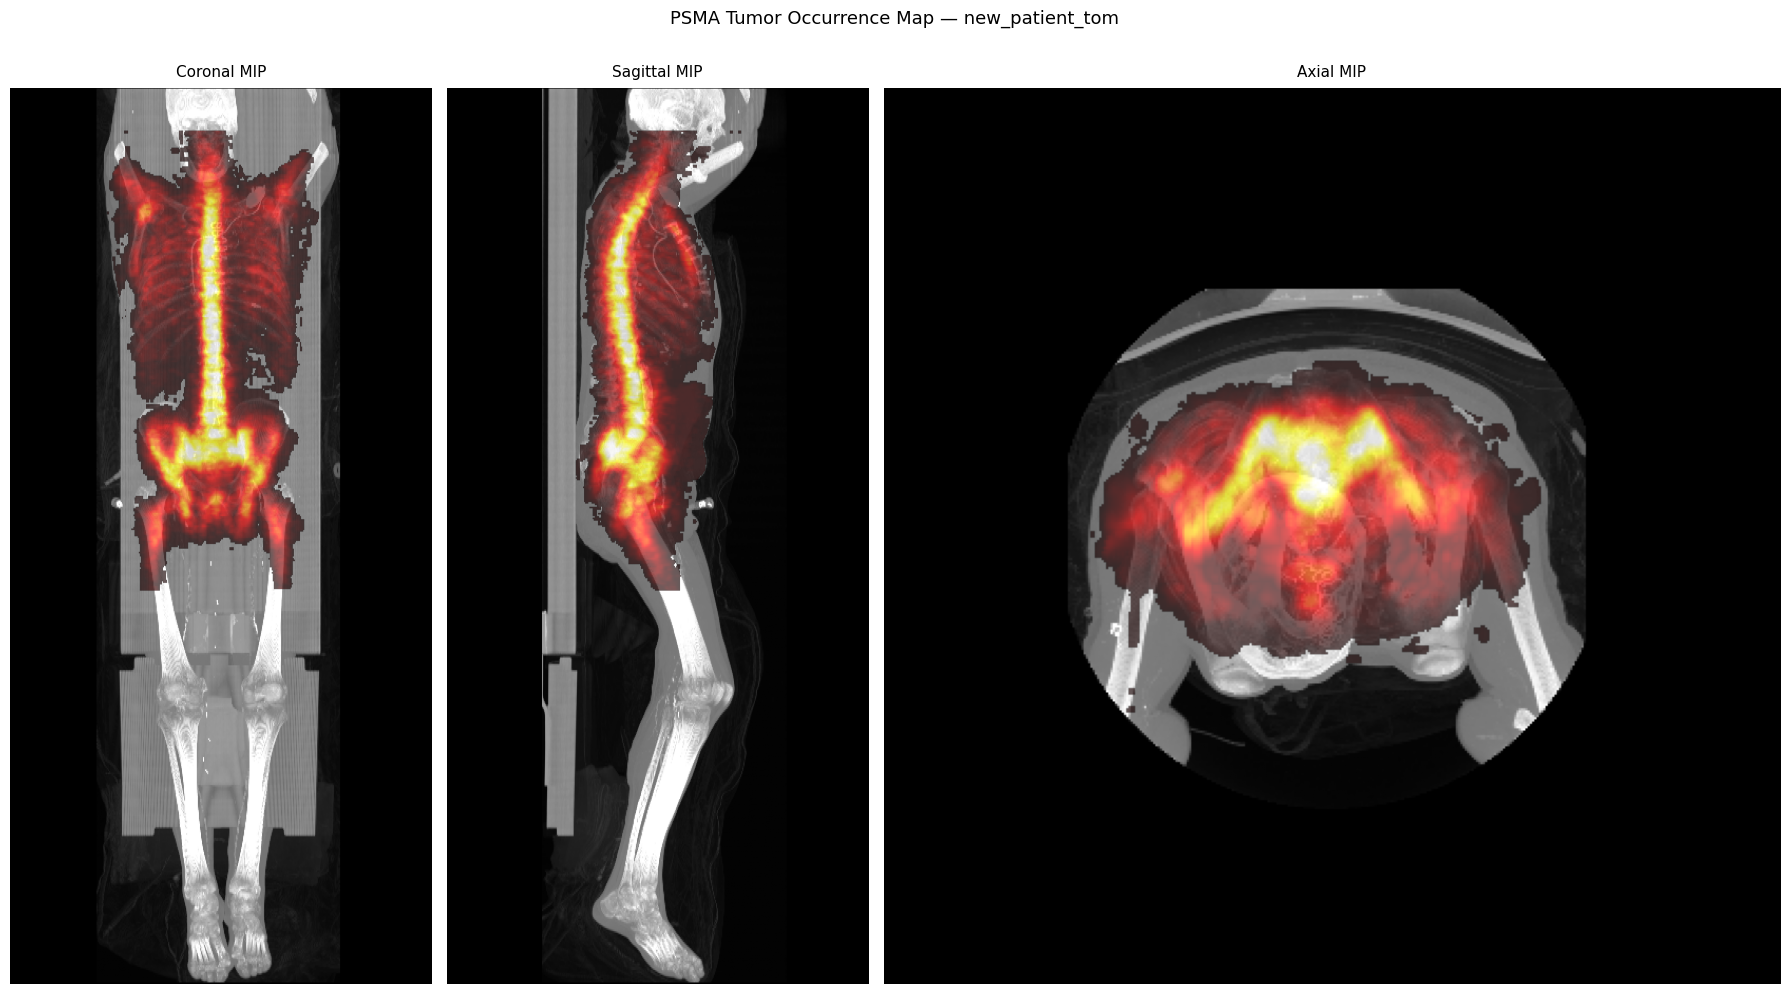

  Saved: TOM_MIP_overlay.png

  Done. All outputs in: /content/drive/MyDrive/FYR/TOM_projected/new_patient_tom


In [ ]:
# ─── Cell 3 · Full pipeline ──────────────────────────────────────────────────
import gc
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk


# ═════════════════════════════════════════════════════════════════════════════
# HELPER FUNCTIONS
# ═════════════════════════════════════════════════════════════════════════════

def load_image(path):
    """Load NIfTI file (.nii/.nii.gz) or DICOM directory."""
    p = Path(path)
    if p.is_dir():
        reader = sitk.ImageSeriesReader()
        ids = reader.GetGDCMSeriesIDs(str(p))
        if not ids:
            raise FileNotFoundError(f"No DICOM series in {p}")
        reader.SetFileNames(reader.GetGDCMSeriesFileNames(str(p), ids[0]))
        return reader.Execute()
    return sitk.ReadImage(str(p))


def body_centroid(ct):
    """
    Physical (x, y, z) centroid of the patient body.
    HU > -300 threshold, largest connected component.
    Falls back to image centre if thresholding finds nothing.
    """
    thresh = sitk.Greater(sitk.Cast(ct, sitk.sitkFloat32), -300.0)
    thresh = sitk.BinaryFillhole(thresh, foregroundValue=1)
    cc     = sitk.ConnectedComponent(thresh)
    st     = sitk.LabelShapeStatisticsImageFilter()
    st.Execute(cc)
    labels = st.GetLabels()
    if not labels:
        sz = ct.GetSize()
        return np.array(ct.TransformIndexToPhysicalPoint([s // 2 for s in sz]))
    return np.array(st.GetCentroid(max(labels, key=st.GetPhysicalSize)))


def body_mask(ct):
    """Binary body mask: HU threshold + largest CC + morphological closing."""
    b  = sitk.Greater(sitk.Cast(ct, sitk.sitkFloat32), -300.0)
    b  = sitk.BinaryFillhole(b, foregroundValue=1)
    cc = sitk.ConnectedComponent(b)
    st = sitk.LabelShapeStatisticsImageFilter()
    st.Execute(cc)
    labels = st.GetLabels()
    if not labels:
        return sitk.Cast(b, sitk.sitkUInt8)
    lg = max(labels, key=st.GetPhysicalSize)
    m  = sitk.BinaryThreshold(cc, lowerThreshold=lg, upperThreshold=lg,
                               insideValue=1, outsideValue=0)
    return sitk.BinaryMorphologicalClosing(sitk.Cast(m, sitk.sitkUInt8), [5] * 3)


def register_template_to_newct(template_ct, new_ct, shrink=4):
    """
    Two-stage registration: centroid translation + affine refinement.

    Stage 1: Align body centroids via translation. This handles arbitrary
             origin/FOV/spacing differences between any two CTs.

    Stage 2: Resample template into new CT grid using centroid translation,
             then refine with affine registration (correlation metric).
             Correlation has no internal histogram so it never crashes.

    Returns a SimpleITK transform (composite or translation-only fallback).
    """
    # ── Stage 1: centroid translation ─────────────────────────────────────
    c_t    = body_centroid(template_ct)
    c_n    = body_centroid(new_ct)
    offset = c_t - c_n

    centroid_tx = sitk.TranslationTransform(3, offset.tolist())

    print(f"  Centroid offset: "
          f"dx={offset[0]:+.1f}  dy={offset[1]:+.1f}  dz={offset[2]:+.1f} mm")

    # ── Stage 2: affine refinement ────────────────────────────────────────
    # Resample template into new CT's exact grid (guaranteed overlap)
    template_aligned = sitk.Resample(
        sitk.Cast(template_ct, sitk.sitkFloat32),
        new_ct, centroid_tx,
        sitk.sitkLinear, -1024.0, sitk.sitkFloat32)

    # Downsample both for speed
    fixed_ds  = sitk.Shrink(sitk.Cast(new_ct, sitk.sitkFloat32), [shrink] * 3)
    moving_ds = sitk.Shrink(template_aligned, [shrink] * 3)

    # Clamp HU (raw values, no z-score — keeps consistent range)
    fixed_ds  = sitk.Cast(
        sitk.Clamp(fixed_ds,  lowerBound=-1024, upperBound=1500),
        sitk.sitkFloat32)
    moving_ds = sitk.Cast(
        sitk.Clamp(moving_ds, lowerBound=-1024, upperBound=1500),
        sitk.sitkFloat32)

    print(f"  Registration grid: {fixed_ds.GetSize()}")

    reg = sitk.ImageRegistrationMethod()
    reg.SetMetricAsCorrelation()
    reg.SetMetricSamplingStrategy(reg.RANDOM)
    reg.SetMetricSamplingPercentage(0.30)
    reg.SetInterpolator(sitk.sitkLinear)
    reg.SetOptimizerAsRegularStepGradientDescent(
        learningRate=1.0, minStep=1e-5,
        numberOfIterations=500, relaxationFactor=0.5)
    reg.SetOptimizerScalesFromPhysicalShift()
    reg.SetShrinkFactorsPerLevel([4, 2, 1])
    reg.SetSmoothingSigmasPerLevel([4.0, 2.0, 0.0])
    reg.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()

    # Body masks so metric ignores background
    try:
        reg.SetMetricFixedMask(body_mask(fixed_ds))
        reg.SetMetricMovingMask(body_mask(moving_ds))
    except Exception:
        pass

    affine_init = sitk.CenteredTransformInitializer(
        fixed_ds, moving_ds, sitk.AffineTransform(3),
        sitk.CenteredTransformInitializerFilter.GEOMETRY)
    reg.SetInitialTransform(affine_init, inPlace=False)

    try:
        tx_refine = reg.Execute(fixed_ds, moving_ds)
        metric    = reg.GetMetricValue()
        print(f"  Affine metric: {metric:.5f}  (negative = good)")

        tx_final = sitk.CompositeTransform(3)
        tx_final.AddTransform(centroid_tx)
        tx_final.AddTransform(tx_refine)
        print("  Result: centroid + affine")
    except Exception as e:
        print(f"  Affine refinement failed ({e}), using centroid only")
        tx_final = centroid_tx

    del fixed_ds, moving_ds, template_aligned
    gc.collect()
    return tx_final


def project_tom(tom, template_ct, new_ct, tx):
    """Upsample TOM to full template res, warp to new CT, body-mask."""
    tom_full   = sitk.Resample(tom, template_ct, sitk.Transform(),
                                sitk.sitkLinear, 0.0, sitk.sitkFloat32)
    tom_warped = sitk.Resample(tom_full, new_ct, tx,
                                sitk.sitkLinear, 0.0, sitk.sitkFloat32)
    tom_warped = sitk.Mask(tom_warped, body_mask(new_ct))
    del tom_full
    gc.collect()
    return tom_warped


def plot_alignment_qc(template_ct, new_ct, tx, save_path):
    """Red/cyan MIP overlay: red = template, cyan = new CT, white = overlap."""
    template_warped = sitk.Resample(
        sitk.Cast(template_ct, sitk.sitkFloat32),
        new_ct, tx, sitk.sitkLinear, -1024.0, sitk.sitkFloat32)

    t_arr = sitk.GetArrayFromImage(template_warped)
    n_arr = sitk.GetArrayFromImage(sitk.Cast(new_ct, sitk.sitkFloat32))

    fig, axes = plt.subplots(1, 3, figsize=(16, 6))
    for col, (name, axis, flip) in enumerate([
            ("Coronal", 1, True), ("Sagittal", 2, True), ("Axial", 0, False)]):
        t_p = t_arr.max(axis=axis).astype(np.float32)
        n_p = n_arr.max(axis=axis).astype(np.float32)
        for p in [t_p, n_p]:
            lo, hi = np.percentile(p, [2, 98])
            p[:] = np.clip((p - lo) / (hi - lo + 1e-8), 0, 1)
        if flip:
            t_p, n_p = np.flipud(t_p), np.flipud(n_p)
        rgb = np.zeros((*n_p.shape, 3))
        rgb[:, :, 0] = t_p * 0.7
        rgb[:, :, 1] = n_p * 0.7
        rgb[:, :, 2] = n_p * 0.7
        axes[col].imshow(rgb, origin="upper")
        axes[col].set_title(f"{name}\n(Red=template, Cyan=newCT)", fontsize=9)
        axes[col].axis("off")
    plt.suptitle("Alignment QC — white = good overlap", fontsize=11)
    plt.tight_layout()
    plt.savefig(str(save_path), dpi=150, bbox_inches="tight")
    plt.show()
    del t_arr, n_arr, template_warped
    gc.collect()


def plot_mips(ct, tom_warped, save_path, title="PSMA TOM on new CT"):
    """
    Publication-quality MIP figure with physically correct aspect ratios.
    Uses the CT voxel spacing to set aspect ratio per view so bodies
    look natural regardless of anisotropic voxel sizes.
    """
    ct_arr  = sitk.GetArrayFromImage(sitk.Cast(ct, sitk.sitkFloat32))
    tom_arr = sitk.GetArrayFromImage(tom_warped)

    sp = ct.GetSpacing()  # (x, y, z)
    # Array axes: (z, y, x)
    # Coronal  = project along y (axis 1) -> (z, x) -> aspect = z_sp / x_sp
    # Sagittal = project along x (axis 2) -> (z, y) -> aspect = z_sp / y_sp
    # Axial    = project along z (axis 0) -> (y, x) -> aspect = y_sp / x_sp
    phys_aspect = {
        "Coronal":  sp[2] / sp[0],
        "Sagittal": sp[2] / sp[1],
        "Axial":    sp[1] / sp[0],
    }

    def _ct_mip(axis):
        p = ct_arr.max(axis=axis)
        lo, hi = np.percentile(p, [2, 98])
        return np.clip((p - lo) / (hi - lo + 1e-8), 0, 1)

    def _tom_mip(axis):
        a = tom_arr.copy()
        a[a < 0.001] = 0
        p   = a.max(axis=axis)
        nz  = p[p > 0]
        p99 = np.percentile(nz, 99) if nz.size else 1.0
        return np.clip(p / (p99 + 1e-8), 0, 1)

    views = [("Coronal", 1, True), ("Sagittal", 2, True), ("Axial", 0, False)]

    # Compute physical panel widths for subplot ratios
    panel_widths = []
    for name, axis, flip in views:
        proj  = ct_arr.max(axis=axis)
        h, w  = proj.shape
        asp   = phys_aspect[name]
        panel_widths.append(w / (h * asp))  # physical width / physical height

    fig, axes = plt.subplots(
        1, 3, figsize=(18, 10),
        gridspec_kw={"width_ratios": panel_widths})

    for col, (name, axis, flip) in enumerate(views):
        ct_p  = _ct_mip(axis)
        tom_p = _tom_mip(axis)
        if flip:
            ct_p  = np.flipud(ct_p)
            tom_p = np.flipud(tom_p)

        asp = phys_aspect[name]
        axes[col].imshow(ct_p, cmap="gray", origin="upper", aspect=asp)
        ov = np.ma.masked_where(tom_p < 0.01, tom_p)
        axes[col].imshow(ov, cmap="hot", vmin=0, vmax=1,
                          alpha=0.65, origin="upper", aspect=asp)
        axes[col].set_title(f"{name} MIP", fontsize=11, pad=8)
        axes[col].axis("off")

    plt.suptitle(title, fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(str(save_path), dpi=300, bbox_inches="tight")
    plt.show()

    del ct_arr, tom_arr
    gc.collect()


# ═════════════════════════════════════════════════════════════════════════════
# MAIN PIPELINE
# ═════════════════════════════════════════════════════════════════════════════

print("=" * 65)
print("  PSMA TOM Projection Pipeline")
print("=" * 65)

# ── 1. Load ───────────────────────────────────────────────────────────────
print("\n[1/5] Loading images ...")
tom         = sitk.Cast(load_image(TOM_PATH), sitk.sitkFloat32)
template_ct = load_image(TEMPLATE_CT_PATH)
new_ct      = load_image(NEW_CT_PATH)

for label, img in [("TOM", tom), ("Template CT", template_ct), ("New CT", new_ct)]:
    sp = [round(s, 1) for s in img.GetSpacing()]
    print(f"  {label:<12s}: {img.GetSize()}  spacing={sp} mm")

# ── 2. Register ───────────────────────────────────────────────────────────
print("\n[2/5] Registration ...")
tx = register_template_to_newct(template_ct, new_ct, shrink=4)

# ── 3. QC ─────────────────────────────────────────────────────────────────
print("\n[3/5] Alignment QC ...")
plot_alignment_qc(template_ct, new_ct, tx, SAVE_DIR / "QC_alignment.png")
print("  Saved: QC_alignment.png")

# ── 4. Warp TOM ──────────────────────────────────────────────────────────
print("\n[4/5] Projecting TOM ...")
tom_warped = project_tom(tom, template_ct, new_ct, tx)

arr = sitk.GetArrayFromImage(tom_warped)
print(f"  Range    : [{arr.min():.4f}, {arr.max():.4f}]")
print(f"  Non-zero : {(arr > 0).sum():,d} ({100 * (arr > 0).mean():.2f}%)")

if arr.max() < 0.001:
    print("\n  WARNING: TOM is all zeros — check QC_alignment.png")
else:
    sitk.WriteImage(tom_warped, str(SAVE_DIR / "TOM_warped.nii.gz"))
    tom_bin = sitk.Cast(
        sitk.BinaryThreshold(tom_warped, lowerThreshold=0.005,
                             upperThreshold=1.0,
                             insideValue=1, outsideValue=0),
        sitk.sitkUInt8)
    sitk.WriteImage(tom_bin, str(SAVE_DIR / "TOM_warped_binary.nii.gz"))
    print("  Saved: TOM_warped.nii.gz")
    print("  Saved: TOM_warped_binary.nii.gz")

# ── 5. MIPs ──────────────────────────────────────────────────────────────
print("\n[5/5] MIP figures ...")
plot_mips(new_ct, tom_warped,
          SAVE_DIR / "TOM_MIP_overlay.png",
          title=f"PSMA Tumor Occurrence Map — {CT_LABEL}")
print("  Saved: TOM_MIP_overlay.png")

del arr, tom_warped
gc.collect()

print("\n" + "=" * 65)
print(f"  Done. All outputs in: {SAVE_DIR}")
print("=" * 65)


## Output files

In [ ]:
# ─── Cell 4 · List outputs ───────────────────────────────────────────────────
print(f"Output: {SAVE_DIR}\n")
for f in sorted(SAVE_DIR.rglob("*.*")):
    print(f"  {f.name:<40s}  {f.stat().st_size / 1e6:>8.1f} MB")


Output: /content/drive/MyDrive/FYR/TOM_projected/new_patient_tom

  MIP_TOM_overlay.png                            1.7 MB
  QC_alignment.png                               0.7 MB
  TOM_MIP_2x3.png                                1.8 MB
  TOM_MIP_final.png                              0.5 MB
  TOM_MIP_overlay.png                            0.7 MB
  TOM_warped.nii.gz                             11.6 MB
  TOM_warped_binary.nii.gz                       0.2 MB
